In [6]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
import matplotlib.pyplot as plt

In [7]:
num_words = 10000
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)
max_sequence_length = 500
X_train = pad_sequences(X_train, maxlen=max_sequence_length)
X_test = pad_sequences(X_test, maxlen=max_sequence_length)

In [8]:
model_names = ['SimpleRNN','LSTM','GRU']
test_losses = []
test_accuracies = []
histories = []

for model_name, layer in zip(model_names, [SimpleRNN, LSTM, GRU]):
    model = Sequential([
        Embedding(input_dim=num_words, output_dim=32, input_length=max_sequence_length),
        layer(32),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2, verbose=0)

    histories.append(history)

    test_loss, test_accuracy = model.evaluate(X_test, y_test)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8349 - loss: 0.4718
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8638 - loss: 0.3619
782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - accuracy: 0.8627 - loss: 0.4027


In [12]:
for model_name, test_loss, test_accuracy in zip(model_names, test_losses, test_accuracies):
    print(f"{model_name} Test loss: {test_loss:.2f}")
    print(f"{model_name} Test accuracy: {test_accuracy* 100:.2f}%")

SimpleRNN Test loss: 0.47
SimpleRNN Test accuracy: 83.49%
LSTM Test loss: 0.36
LSTM Test accuracy: 86.38%
GRU Test loss: 0.40
GRU Test accuracy: 86.27%


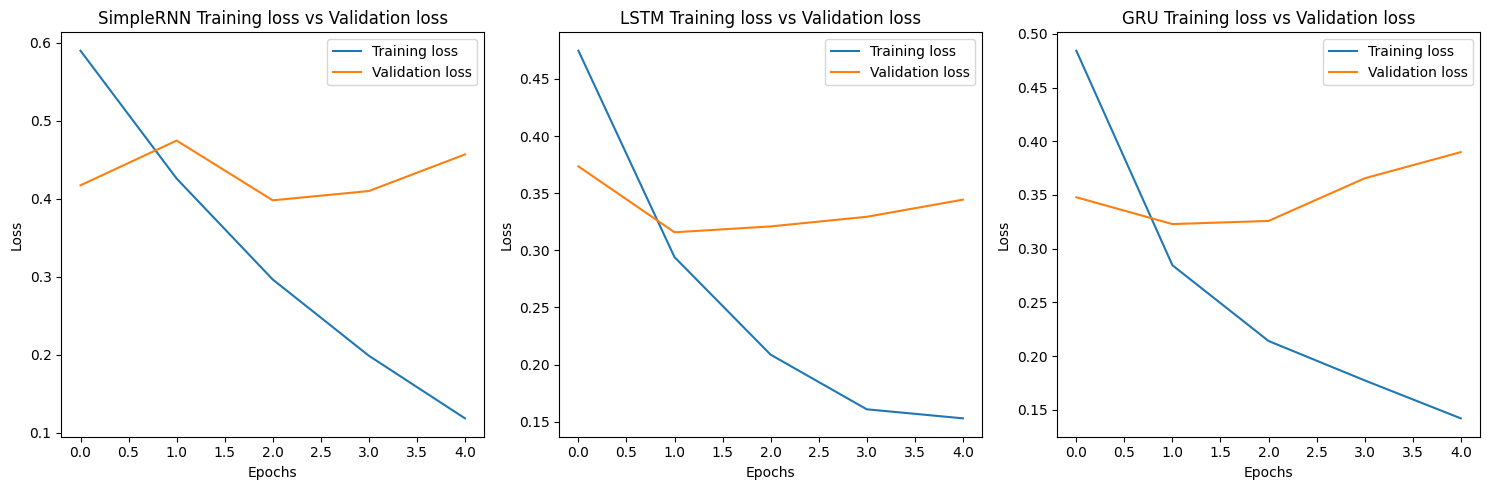

In [21]:
plt.figure(figsize=(15,5))
for i, (model_name, history) in enumerate(zip(model_names, histories)):
    plt.subplot(1,3,i+1)
    plt.plot(history.history['loss'], label='Training loss')
    plt.plot(history.history['val_loss'], label='Validation loss')
    plt.title(f"{model_name} Training loss vs Validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
plt.tight_layout()
plt.show()